In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [89]:
er_data = pd.read_csv("/content/Hospital ER_Data.csv")

In [ ]:
er_data.head()

In [91]:
er_data.shape

(9216, 12)

In [92]:
er_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9216 entries, 0 to 9215
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient Id                  9216 non-null   object 
 1   Patient Admission Date      9216 non-null   object 
 2   Patient First Inital        9216 non-null   object 
 3   Patient Last Name           9216 non-null   object 
 4   Patient Gender              9216 non-null   object 
 5   Patient Age                 9216 non-null   int64  
 6   Patient Race                9216 non-null   object 
 7   Department Referral         3816 non-null   object 
 8   Patient Admission Flag      9216 non-null   bool   
 9   Patient Satisfaction Score  2517 non-null   float64
 10  Patient Waittime            9216 non-null   int64  
 11  Patients CM                 9216 non-null   int64  
dtypes: bool(1), float64(1), int64(3), object(7)
memory usage: 801.1+ KB


In [93]:
er_data.dtypes

,0
Patient Id,object
Patient Admission Date,object
Patient First Inital,object
Patient Last Name,object
Patient Gender,object
Patient Age,int64
Patient Race,object
Department Referral,object
Patient Admission Flag,bool
Patient Satisfaction Score,float64


In [94]:
er_data.columns

Index(['Patient Id', 'Patient Admission Date', 'Patient First Inital',
       'Patient Last Name', 'Patient Gender', 'Patient Age', 'Patient Race',
       'Department Referral', 'Patient Admission Flag',
       'Patient Satisfaction Score', 'Patient Waittime', 'Patients CM'],
      dtype='object')

In [95]:
er_data.columns = (er_data.columns.str.lower().str.replace(" ","_"))

In [96]:
# fixing datatime columns

er_data.patient_admission_date = pd.to_datetime(er_data.patient_admission_date)


/tmp/ipykernel_657/3063148112.py:3: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  er_data.patient_admission_date = pd.to_datetime(er_data.patient_admission_date)


Missing values and duplicate values


In [97]:
er_data.isnull().sum()

,0
patient_id,0
patient_admission_date,0
patient_first_inital,0
patient_last_name,0
patient_gender,0
patient_age,0
patient_race,0
department_referral,5400
patient_admission_flag,0
patient_satisfaction_score,6699


In [98]:
missing_pct = er_data.isnull().sum()/len(er_data)*100

In [99]:
print(missing_pct)

patient_id                     0.000000
patient_admission_date         0.000000
patient_first_inital           0.000000
patient_last_name              0.000000
patient_gender                 0.000000
patient_age                    0.000000
patient_race                   0.000000
department_referral           58.593750
patient_admission_flag         0.000000
patient_satisfaction_score    72.688802
patient_waittime               0.000000
patients_cm                    0.000000
dtype: float64


In [100]:
er_data.duplicated().sum()

np.int64(0)

In [101]:
er_data.duplicated(subset='patient_id').sum()

np.int64(0)

In [102]:
er_data = er_data.drop_duplicates()

In [103]:
er_data['department_referral'] = er_data['department_referral'].fillna("unknown")

In [104]:
# Reloading the original data to fix the corrupted column values
temp_df = pd.read_csv("/content/Hospital ER_Data.csv")
er_data['patient_satisfaction_score'] = temp_df['Patient Satisfaction Score']

# Safely calculating the median score
med_score = er_data['patient_satisfaction_score'].median()
print("Median satisfaction score:", med_score)

Median satisfaction score: 5.0


In [105]:
# er_data['patient_satisfaction_score'] = er_data['patient_satisfaction_score'].fillna(0)

In [106]:
er_data['patient_satisfaction_score'] = er_data['patient_satisfaction_score'].fillna(med_score)

In [107]:
# feature engineering

er_data['year'] = er_data['patient_admission_date'].dt.year
er_data['month'] = er_data['patient_admission_date'].dt.month
er_data['weekday'] = er_data['patient_admission_date'].dt.weekday
er_data['day_name'] = er_data['patient_admission_date'].dt.day_name()
er_data['month_name'] = er_data['patient_admission_date'].dt.month_name()
er_data['hour'] = er_data['patient_admission_date'].dt.hour

In [108]:
def age_group(val):
  if val <=5:
    return "infant"
  elif val > 5 and val <=12:
    return "child"
  elif val >13 and val<=19:
    return "young adult"
  elif val > 19 and val <= 30:
    return "adult"
  elif val >30 and val<=50:
    return "middle age"
  else:
    return "senior"

In [109]:
er_data["age_group"] = er_data['patient_age'].apply(age_group)

In [110]:
er_data['age_group'].head()

,age_group
0,senior
1,infant
2,senior
3,adult
4,infant


In [111]:
er_data["name"] = er_data["patient_first_inital"] + " " + er_data["patient_last_name"]

In [ ]:
er_data["name"].head()

In [113]:
er_data.columns

Index(['patient_id', 'patient_admission_date', 'patient_first_inital',
       'patient_last_name', 'patient_gender', 'patient_age', 'patient_race',
       'department_referral', 'patient_admission_flag',
       'patient_satisfaction_score', 'patient_waittime', 'patients_cm', 'year',
       'month', 'weekday', 'day_name', 'month_name', 'hour', 'age_group',
       'name'],
      dtype='object')

Univariate analysis

In [114]:
for col in ['patient_gender', 'patient_race', 'department_referral', 'patient_admission_flag' ] :
  print(er_data[col].value_counts(normalize=True).round(3), '\n')

patient_gender
M     0.511
F     0.487
NC    0.003
Name: proportion, dtype: float64 

patient_race
White                            0.279
African American                 0.212
Two or More Races                0.169
Asian                            0.115
Declined to Identify             0.112
Pacific Islander                 0.060
Native American/Alaska Native    0.054
Name: proportion, dtype: float64 

department_referral
unknown             0.586
General Practice    0.200
Orthopedics         0.108
Physiotherapy       0.030
Cardiology          0.027
Neurology           0.021
Gastroenterology    0.019
Renal               0.009
Name: proportion, dtype: float64 

patient_admission_flag
True     0.5
False    0.5
Name: proportion, dtype: float64 



In [115]:
er_data['patient_gender'].value_counts()

,count
patient_gender,
M,4705
F,4487
NC,24


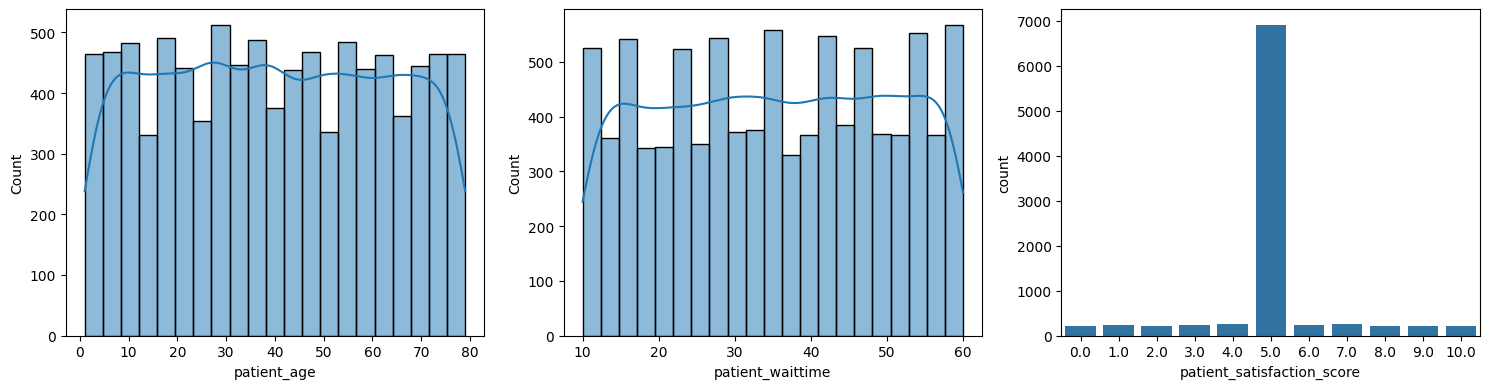

In [116]:
fig, ax = plt.subplots(1,3, figsize = (15,4))
sns.histplot(er_data['patient_age'], ax=ax[0], kde=True)
sns.histplot(er_data['patient_waittime'], ax=ax[1], kde=True)
sns.countplot(x='patient_satisfaction_score', data=er_data, ax=ax[2])
plt.tight_layout();
plt.show()

Outlier Detection

0


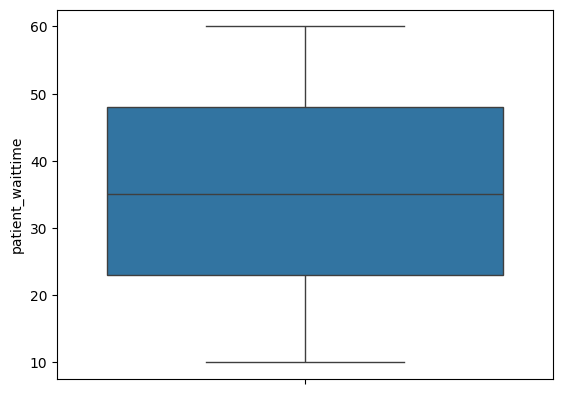

In [117]:
sns.boxplot(er_data['patient_waittime'])

Q1 = er_data['patient_waittime'].quantile(0.25)
Q3 = er_data['patient_waittime'].quantile(0.75)
IQR = Q3 - Q1

outliers = er_data[(er_data['patient_waittime'] < Q1 -1.5*IQR) | (er_data['patient_waittime'] > Q3 + 1.5*IQR)]

print(len(outliers))

Bivariate analysis(core insights)

In [118]:
# wait time by dept

er_data.groupby('department_referral')['patient_waittime'].agg(['mean', 'median', 'count']).sort_values(by='mean', ascending=False)

,mean,median,count
department_referral,,,
Neurology,36.803109,38.0,193
Physiotherapy,36.565217,38.5,276
Gastroenterology,35.831461,36.0,178
Cardiology,35.354839,35.0,248
unknown,35.293148,35.0,5400
Orthopedics,34.982915,34.0,995
General Practice,34.912500,35.0,1840
Renal,34.697674,35.0,86


,patient_satisfaction_score,patient_waittime,patient_age
patient_satisfaction_score,1.000000,-0.011165,-0.012424
patient_waittime,-0.011165,1.000000,-0.005636
patient_age,-0.012424,-0.005636,1.000000


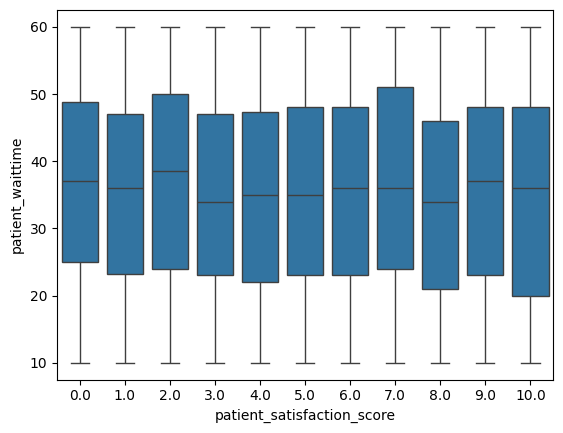

In [119]:
# Satisfaction vs wait time
sns.boxplot(x = 'patient_satisfaction_score', y='patient_waittime', data=er_data)
er_data[['patient_satisfaction_score', 'patient_waittime', 'patient_age']].corr()

In [120]:
# admission rate by age group / gender / race
pd.crosstab(er_data['age_group'], er_data['patient_admission_flag'], normalize='index')

patient_admission_flag,False,True
age_group,,
adult,0.499235,0.500765
child,0.488677,0.511323
infant,0.493031,0.506969
middle age,0.504296,0.495704
senior,0.502464,0.497536
young adult,0.488858,0.511142


<Axes: xlabel='patient_race', ylabel='patient_waittime'>

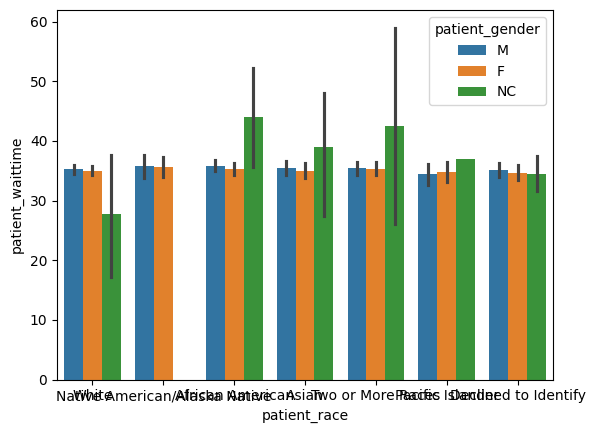

In [121]:
# wait time by gender and race
sns.barplot(x='patient_race', y='patient_waittime', hue='patient_gender', data=er_data)

Time series analysis

<Axes: title={'center': 'Daily ER Visits'}, xlabel='patient_admission_date'>

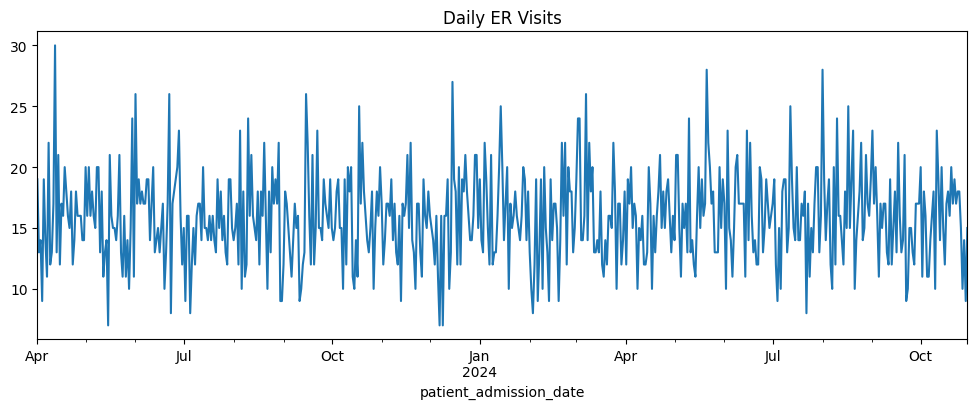

In [122]:
daily = er_data.set_index('patient_admission_date').resample('D').size()
daily.plot(figsize=(12,4), title = 'Daily ER Visits')



<Axes: xlabel='weekday', ylabel='count'>

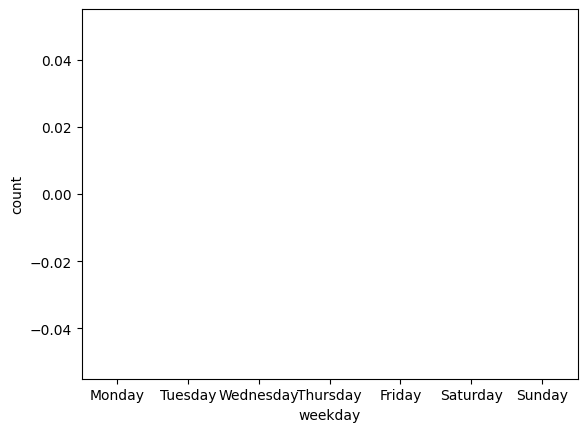

In [123]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
sns.countplot(x='weekday', data=er_data, order=order)

<Axes: xlabel='weekday', ylabel='month'>

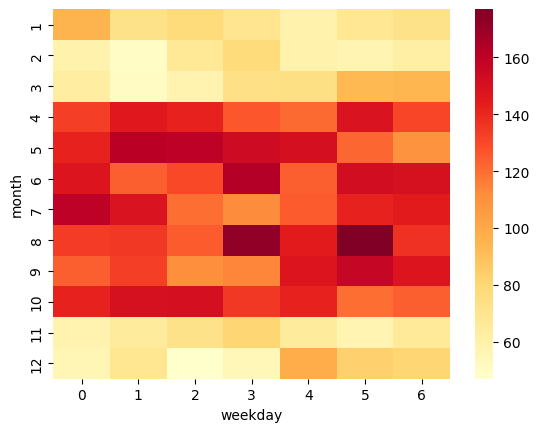

In [124]:
# month X weekday heatmap
sns.heatmap(pd.crosstab(er_data['month'], er_data['weekday']), cmap='YlOrRd')

Crrelation Heatmap

<Axes: >

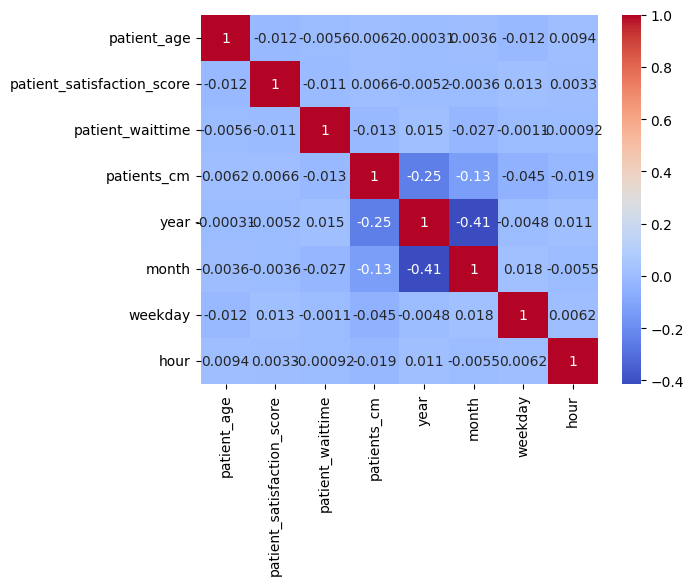

In [125]:
sns.heatmap(er_data.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm')

Statistical tests


In [126]:
from scipy import stats

In [127]:
er_data['patient_gender'].head()

,patient_gender
0,M
1,M
2,F
3,F
4,M


In [128]:
# does wait time differs by gender

m = er_data[er_data.patient_gender == 'M']['patient_waittime']
f = er_data[er_data.patient_gender == 'F']['patient_waittime']

print(stats.ttest_ind(m,f, nan_policy='omit'))

TtestResult(statistic=np.float64(0.9494017398017156), pvalue=np.float64(0.3424412913134455), df=np.float64(9190.0))


In [129]:
# does wait time differ across departments
groups = [group['patient_waittime'] for name, group in er_data.groupby('department_referral')]
print(stats.f_oneway(*groups))

F_onewayResult(statistic=np.float64(0.8695921223980334), pvalue=np.float64(0.5296532350307224))


In [130]:
# is admission associated with department
ct = pd.crosstab(er_data['department_referral'], er_data['patient_admission_flag'])
print(stats.chi2_contingency(ct))  # chi2, p-value

Chi2ContingencyResult(statistic=np.float64(3.8242496476478087), pvalue=np.float64(0.7997833577416127), dof=7, expected_freq=array([[ 123.89236111,  124.10763889],
       [  88.92274306,   89.07725694],
       [ 919.20138889,  920.79861111],
       [  96.41623264,   96.58376736],
       [ 497.06814236,  497.93185764],
       [ 137.88020833,  138.11979167],
       [  42.96267361,   43.03732639],
       [2697.65625   , 2702.34375   ]]))


In [131]:
# which dept has longest waits?

dept_wait = (er_data.groupby('department_referral').agg(avg_wait=('patient_waittime','mean'),median_wait= ('patient_waittime','median'), patients = ('patient_waittime','count')).sort_values(by='avg_wait', ascending=False).round(1).sort_values('avg_wait', ascending=False))

print(dept_wait)

                     avg_wait  median_wait  patients
department_referral                                 
Neurology                36.8         38.0       193
Physiotherapy            36.6         38.5       276
Gastroenterology         35.8         36.0       178
Cardiology               35.4         35.0       248
unknown                  35.3         35.0      5400
Orthopedics              35.0         34.0       995
General Practice         34.9         35.0      1840
Renal                    34.7         35.0        86


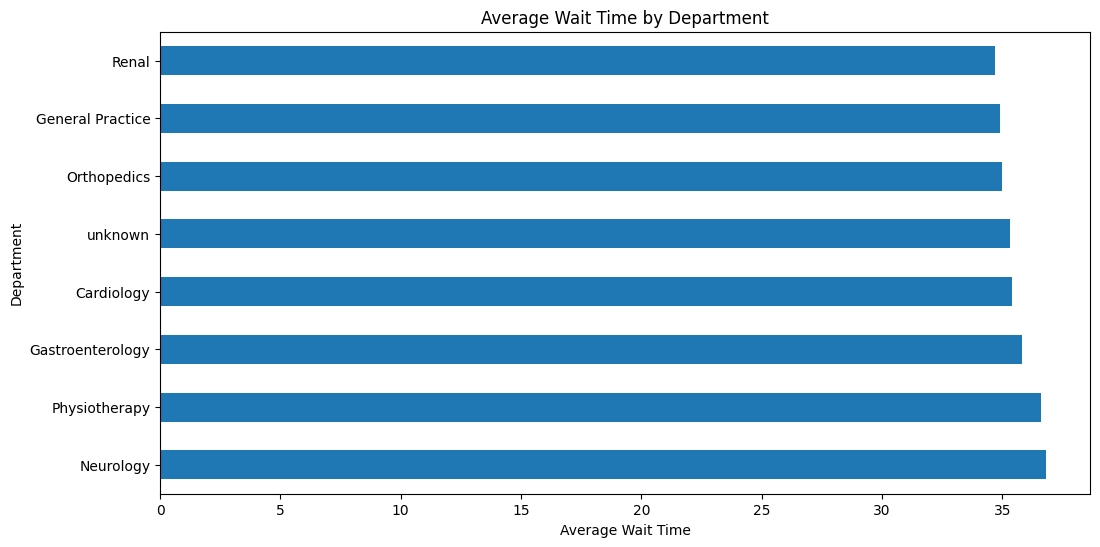

In [132]:
dept_wait['avg_wait'].sort_values(ascending=False).plot(kind='barh', figsize=(12,6))
plt.xlabel('Average Wait Time')
plt.ylabel('Department')
plt.title('Average Wait Time by Department')
plt.show()

In [133]:
print(max(dept_wait['avg_wait']))

36.8


In [134]:
longest_dept, longest_wait = dept_wait.index[0], dept_wait.iloc[0]

shortest_dept, shortest_wait = dept_wait.index[-1], dept_wait.iloc[-1]

print(f"The department with the longest average wait time is {longest_dept} with an average wait time of {longest_wait} minutes.")

print(f"the {shortest_dept} have the shortest wait time of {shortest_wait} mins")

The department with the longest average wait time is Neurology with an average wait time of avg_wait        36.8
median_wait     38.0
patients       193.0
Name: Neurology, dtype: float64 minutes.
the Renal have the shortest wait time of avg_wait       34.7
median_wait    35.0
patients       86.0
Name: Renal, dtype: float64 mins


In [135]:
from scipy import stats
groups = [g['patient_waittime'].dropna() for _, g in er_data.groupby('department_referral')]
print(stats.f_oneway(*groups))

F_onewayResult(statistic=np.float64(0.8695921223980334), pvalue=np.float64(0.5296532350307224))


In [136]:
# Does a longer wait lower satisfaction?

er_data.groupby('patient_satisfaction_score')['patient_waittime'].agg(['mean', 'median', 'count']).sort_values(by='mean', ascending=False)

,mean,median,count
patient_satisfaction_score,,,
2.0,36.887255,38.5,204
0.0,36.108108,37.0,222
7.0,35.910156,36.0,256
6.0,35.588745,36.0,231
1.0,35.373984,36.0,246
9.0,35.265766,37.0,222
10.0,35.248869,36.0,221
5.0,35.221243,35.0,6920
3.0,35.092105,34.0,228


In [137]:
er_data['patient_waittime'].corr(er_data['patient_satisfaction_score'], method='spearman')

np.float64(-0.00789446359548945)

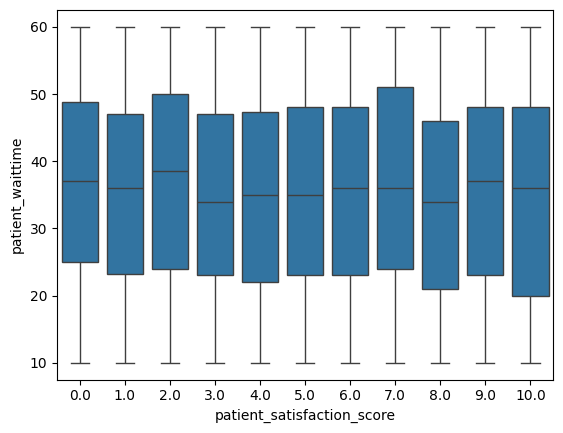

In [138]:
sns.boxplot(x='patient_satisfaction_score', y='patient_waittime', data=er_data)
plt.show()

In [139]:
# Peak days/hours/months for visits?

# peak days of week
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekdays_counts = er_data['day_name'].value_counts().reindex(days)

print(weekdays_counts)


day_name
Monday       1314
Tuesday      1305
Wednesday    1260
Thursday     1332
Friday       1310
Saturday     1377
Sunday       1318
Name: count, dtype: int64


In [140]:
er_data['day_name'].head(10)

,day_name
0,Wednesday
1,Saturday
2,Thursday
3,Sunday
4,Wednesday
5,Thursday
6,Wednesday
7,Saturday
8,Monday
9,Friday


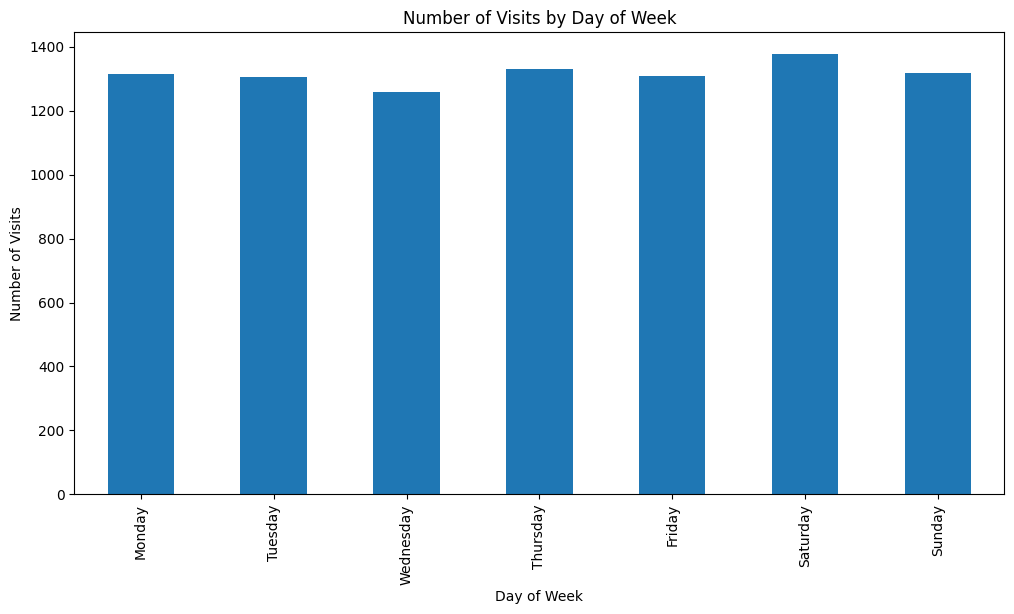

In [141]:

weekdays_counts.plot(kind='bar', figsize=(12,6))
plt.xlabel('Day of Week')
plt.ylabel('Number of Visits')
plt.title('Number of Visits by Day of Week')
plt.show()

In [142]:
# peak hours

hour_counts = er_data['hour'].value_counts().sort_index()

print(hour_counts)

hour
0     406
1     372
2     376
3     385
4     384
5     393
6     375
7     415
8     386
9     388
10    349
11    403
12    366
13    410
14    368
15    394
16    378
17    359
18    370
19    383
20    372
21    376
22    372
23    436
Name: count, dtype: int64


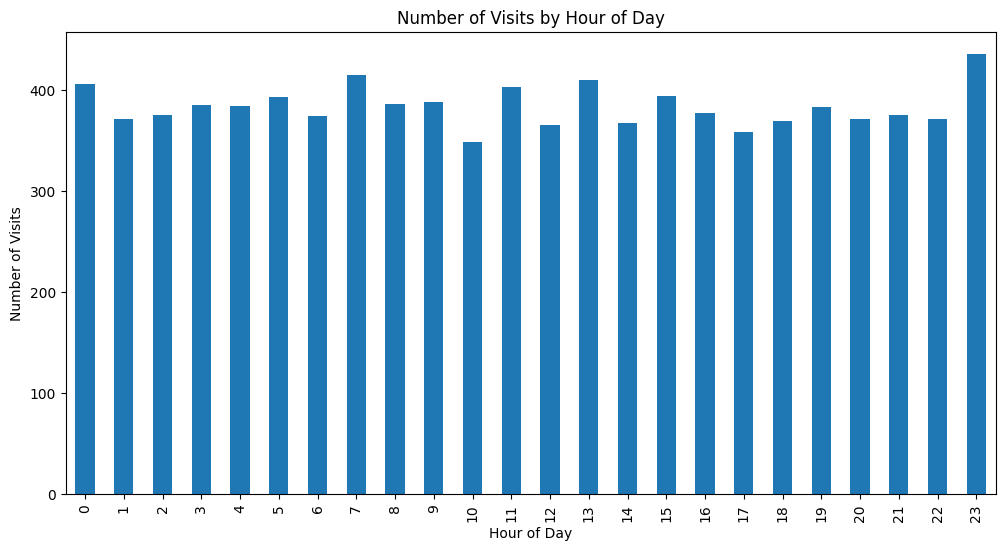

In [143]:
hour_counts.plot(kind='bar', figsize=(12,6))
plt.xlabel('Hour of Day')
plt.ylabel('Number of Visits')
plt.title('Number of Visits by Hour of Day')
plt.show()

In [144]:
# peak months

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

month_counts = er_data['month_name'].value_counts().reindex(month_order)
print(month_counts)

month_name
January       513
February      431
March         506
April         948
May           999
June          991
July          952
August       1024
September     935
October       964
November      464
December      489
Name: count, dtype: int64


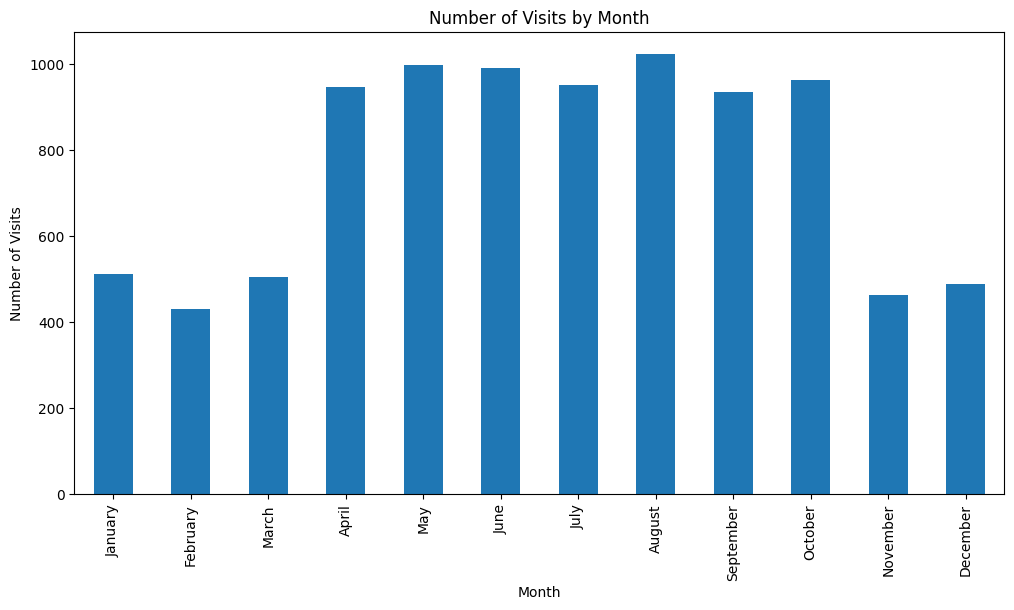

In [145]:
month_counts.plot(kind='bar', figsize=(12,6))
plt.xlabel('Month')
plt.ylabel('Number of Visits')
plt.title('Number of Visits by Month')
plt.show()


In [146]:
# in one sentence
print(f"Peak day: {weekdays_counts.idxmax()} ({weekdays_counts.max()} visits)")
print(f"Peak hour: {hour_counts.idxmax()}:00 ({hour_counts.max()} visits)")
print(f"Peak month: {month_counts.idxmax()} ({month_counts.max()} visits)")

Peak day: Saturday (1377 visits)
Peak hour: 23:00 (436 visits)
Peak month: August (1024 visits)


In [147]:
# Which age group is admitted most?

age_group_count = er_data['age_group'].value_counts()

print(age_group_count)

age_group
senior         3449
middle age     2328
adult          1308
child           839
young adult     718
infant          574
Name: count, dtype: int64


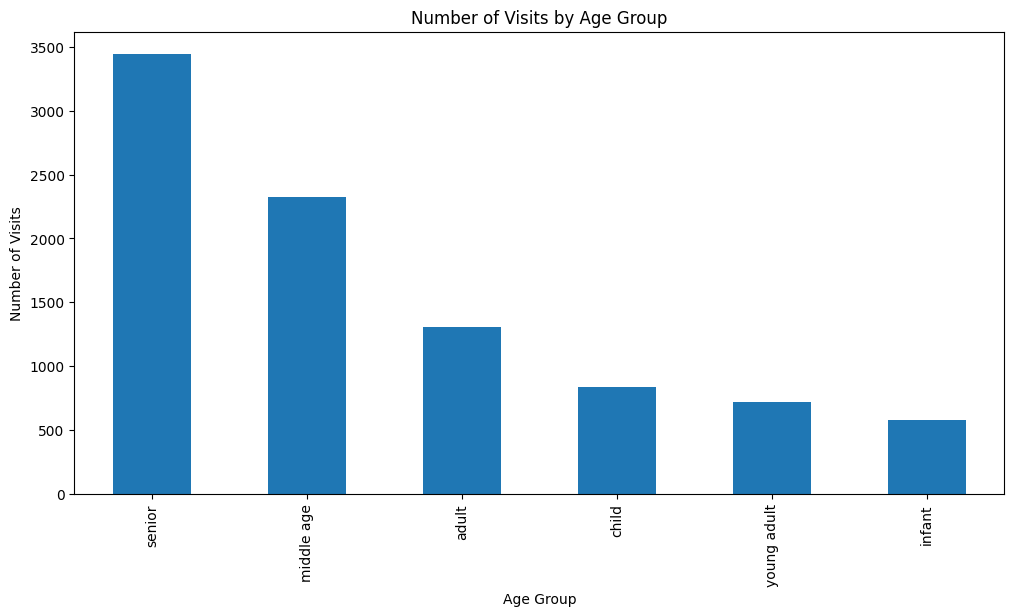

In [148]:
age_group_count.plot(kind='bar', figsize=(12,6))
plt.xlabel('Age Group')
plt.ylabel('Number of Visits')
plt.title('Number of Visits by Age Group')
plt.show()

In [149]:
# in one sentence
print(f"the age group of {age_group_count.idxmax()} visited most with visits of {age_group_count.max()} times")
print(  f"the age group of {age_group_count.idxmin()} visited least with visits of {age_group_count.min()} times")

the age group of senior visited most with visits of 3449 times
the age group of infant visited least with visits of 574 times


In [150]:
# Are there disparities in wait time by race or gender?

for col in ['patient_gender', 'patient_race']:
  print(er_data.groupby(col)['patient_waittime'].agg(['mean', 'median', 'count']).sort_values(by='mean', ascending=False))

                     mean  median  count
patient_gender                          
NC              37.166667    37.5     24
M               35.397450    36.0   4705
F               35.105416    35.0   4487
                                    mean  median  count
patient_race                                           
Native American/Alaska Native  35.692771    36.0    498
African American               35.608406    36.0   1951
Two or More Races              35.357739    36.0   1557
Asian                          35.269811    35.0   1060
White                          35.105406    35.0   2571
Declined to Identify           34.943689    35.0   1030
Pacific Islander               34.648452    34.0    549


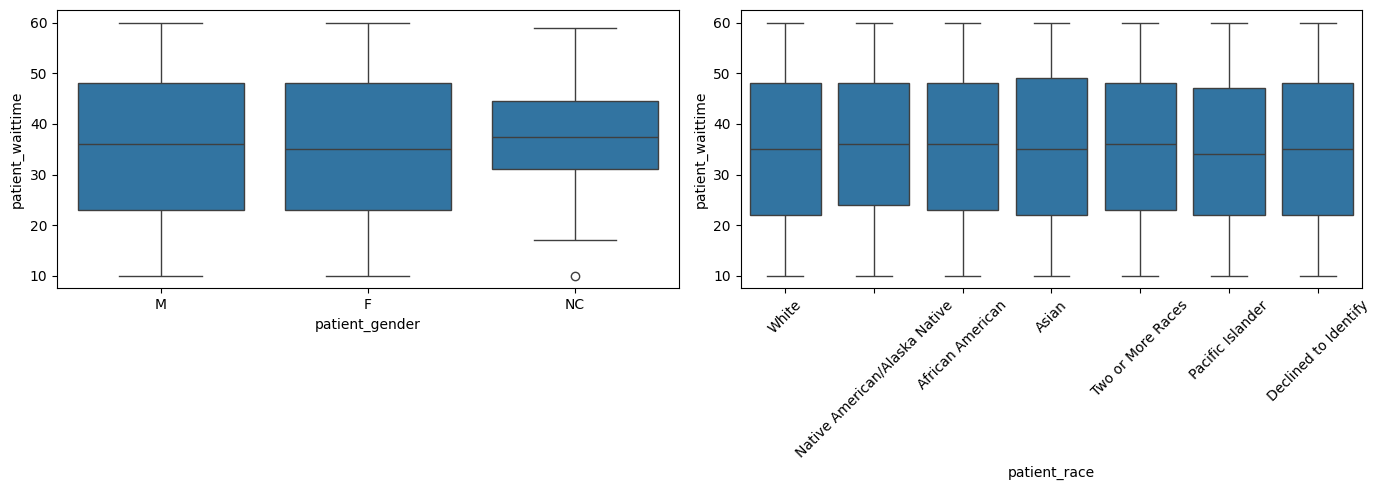

In [151]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='patient_gender', y='patient_waittime', data=er_data, ax=ax[0])
sns.boxplot(x='patient_race', y='patient_waittime', data=er_data, ax=ax[1])
ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()



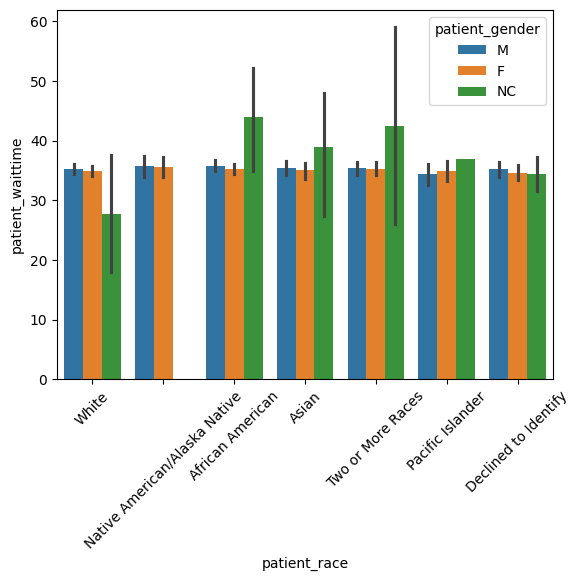

In [152]:
# Race x gender together
sns.barplot(x='patient_race', y='patient_waittime', hue='patient_gender', data=er_data)
plt.xticks(rotation=45); plt.show()

In [153]:
er_data['patient_waittime'].skew()

np.float64(-0.020404557417217827)

In [154]:
# testing wheather differences are statistically significant

from scipy import stats

# gender
g = [grp['patient_waittime'].dropna() for _, grp in er_data.groupby('patient_gender')]
print(stats.mannwhitneyu(g[0],g[1]))

# race
r = [grp['patient_waittime'].dropna() for _, grp in er_data.groupby('patient_race')]
print(stats.kruskal(*r))
print(stats.f_oneway(*r))

MannwhitneyuResult(statistic=np.float64(10433842.5), pvalue=np.float64(0.33799767285149207))
KruskalResult(statistic=np.float64(3.2644493126078173), pvalue=np.float64(0.774998237412856))
F_onewayResult(statistic=np.float64(0.5485829010796465), pvalue=np.float64(0.7714545724644724))


In [155]:
er_data.pivot_table(values='patient_waittime', index='department_referral', columns='patient_gender', aggfunc='mean').round(1)

patient_gender,F,M,NC
department_referral,,,
Cardiology,35.1,35.6,NaN
Gastroenterology,34.5,37.9,10.0
General Practice,35.1,34.7,39.2
Neurology,36.7,36.9,NaN
Orthopedics,34.5,35.4,30.0
Physiotherapy,36.0,37.2,NaN
Renal,35.5,33.9,NaN
unknown,35.1,35.4,39.8


In [156]:
# Which department gets the most referrals?

dept_referral_count = er_data['department_referral'].value_counts()

print(dept_referral_count)

department_referral
unknown             5400
General Practice    1840
Orthopedics          995
Physiotherapy        276
Cardiology           248
Neurology            193
Gastroenterology     178
Renal                 86
Name: count, dtype: int64


In [157]:
print(f"The department with the most referrals is {dept_referral_count.idxmax()} with {dept_referral_count.max()} referrals.")

The department with the most referrals is unknown with 5400 referrals.


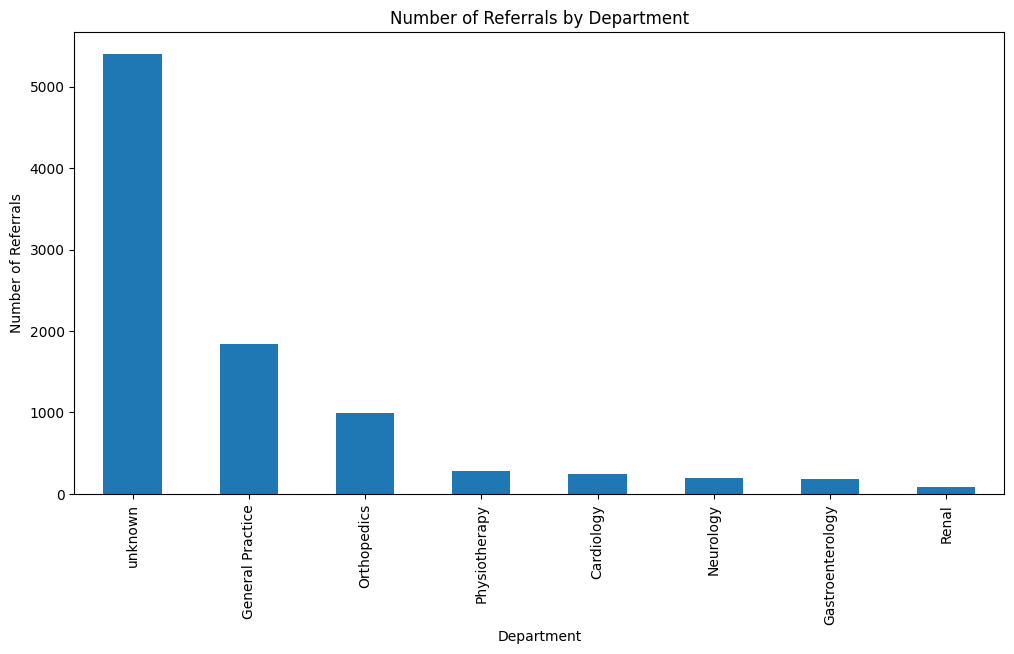

In [158]:
dept_referral_count.plot(kind='bar', figsize=(12,6))
plt.xlabel('Department')
plt.ylabel('Number of Referrals')
plt.title('Number of Referrals by Department')
plt.show()

applying a ML concept

In [159]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [160]:
features = ['patient_age', 'patient_gender', 'patient_race',
            'department_referral', 'patient_waittime']


In [161]:
df_ml = er_data[features + ['patient_admission_flag']].dropna()

In [162]:
X = pd.get_dummies(df_ml[features])
y = df_ml['patient_admission_flag']

In [163]:
X_train, X_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [164]:
model = RandomForestClassifier(random_state=42, class_weight='balanced')

model.fit(X_train, y_train)

y_pred = model.predict(X_test)


In [165]:
print(f"classification report : {classification_report(y_test, y_pred)}")


classification report :               precision    recall  f1-score   support

       False       0.50      0.53      0.52       918
        True       0.51      0.48      0.50       926

    accuracy                           0.51      1844
   macro avg       0.51      0.51      0.51      1844
weighted avg       0.51      0.51      0.51      1844



In [166]:
print(f"confusion matrix : {confusion_matrix(y_test, y_pred)}")

confusion matrix : [[485 433]
 [477 449]]


In [167]:
# er_clean = er_data.copy()

# # Friendly labels for the dashboard
# er_clean['admission_status'] = er_clean['patient_admission_flag'].map({True: 'Admitted', False: 'Not Admitted'})
# er_clean['wait_bucket'] = pd.cut(er_clean['patient_waittime'],
#                                  bins=[0, 15, 30, 45, 60, np.inf],
#                                  labels=['0-15', '15-30', '30-45', '45-60', '60+'])
# er_clean['admission_date'] = er_clean['patient_admission_date'].dt.date
# er_clean['weekday_num'] = er_clean['patient_admission_date'].dt.dayofweek   # for sorting
# er_clean['month_num']   = er_clean['patient_admission_date'].dt.month       # for sorting

# er_clean.to_csv('er_clean.csv', index=False)

In [168]:
er_data.columns

Index(['patient_id', 'patient_admission_date', 'patient_first_inital',
       'patient_last_name', 'patient_gender', 'patient_age', 'patient_race',
       'department_referral', 'patient_admission_flag',
       'patient_satisfaction_score', 'patient_waittime', 'patients_cm', 'year',
       'month', 'weekday', 'day_name', 'month_name', 'hour', 'age_group',
       'name'],
      dtype='object')

In [169]:
safe = er_data.drop(columns = ['patient_id','patient_last_name','patient_first_inital'])
safe.sample(200, random_state=42).to_csv('er_sample.csv', index=False)